# NASA-TLX spider chart: reading vs copy typing


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

DATA = "RvsT_NASA_TLX.csv"
SCALE = 1      # top of the scale: 1 plots 0-1, 100 plots 0-100
ZOOM = 0.75    # outer ring of the display as a share of the full scale; 1 shows the whole range
TITLE = "NASA-TLX: reading vs copy typing"
SUBSCALES = ["Mental_demand", "Physical_demand", "Temporal_demand",
             "Performance", "Effort", "Frustration"]
# session code in the CSV -> (legend label, colour, marker)
SESSIONS = {"Read": ("Reading", "#2a78d6", "o"),
            "Type": ("Copy typing", "#eb6834", "s")}

df = pd.read_csv(DATA)
df = df.groupby("Participant_ID").filter(lambda g: set(g["Session"]) == set(SESSIONS))
entered_on = 1 if df[SUBSCALES].max().max() <= 1 else 100   # scale the ratings were entered on
df[SUBSCALES] = df[SUBSCALES] * SCALE / entered_on
means = df.groupby("Session")[SUBSCALES].mean().loc[list(SESSIONS)]

# paired t-test per subscale (Type vs Read), then Holm correction across the six
wide = df.pivot(index="Participant_ID", columns="Session", values=SUBSCALES)
p = np.array([stats.ttest_rel(wide[s]["Type"], wide[s]["Read"]).pvalue for s in SUBSCALES])
order = np.argsort(p)
p_holm = np.empty_like(p)
p_holm[order] = np.minimum(1, np.maximum.accumulate(p[order] * np.arange(len(p), 0, -1)))

def stars(q):
    return "***" if q < .001 else "**" if q < .01 else "*" if q < .05 else ""

summary = means.T.round(4)
summary["p_holm"] = p_holm.round(4)
summary["sig"] = [stars(q) for q in p_holm]
print(f"n = {df['Participant_ID'].nunique()} participants with both sessions, scale 0-{SCALE}")
summary

n = 24 participants with both sessions, scale 0-1


Session,Read,Type,p_holm,sig
Mental_demand,0.6125,0.5229,0.5735,
Physical_demand,0.2500,0.4708,0.0239,*
Temporal_demand,0.2771,0.4396,0.0237,*
Performance,0.4542,0.4375,0.9573,
Effort,0.5000,0.5479,0.9573,
Frustration,0.3604,0.4417,0.9573,


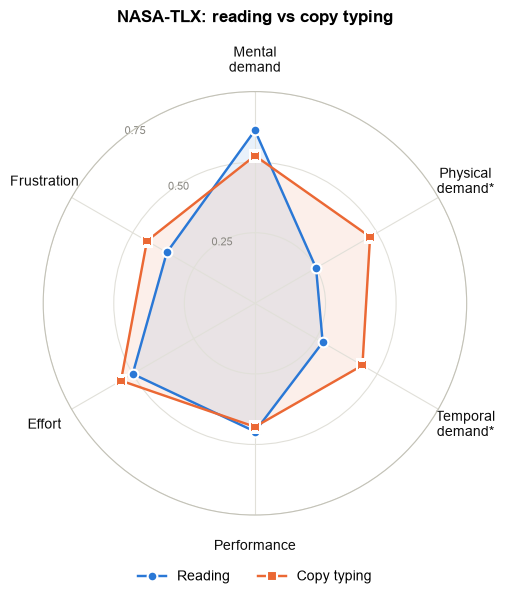

In [2]:
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "Liberation Sans", "DejaVu Sans"]

angles = np.linspace(0, 2 * np.pi, len(SUBSCALES), endpoint=False)
loop = np.append(angles, angles[0])   # repeat the first point to close each shape

fig, ax = plt.subplots(figsize=(5.5, 5.5), subplot_kw={"projection": "polar"})
ax.set_theta_offset(np.pi / 2)        # first subscale at the top
ax.set_theta_direction(-1)            # then clockwise, in TLX form order

for session, (label, colour, marker) in SESSIONS.items():
    values = means.loc[session].to_numpy()
    values = np.append(values, values[0])
    ax.plot(loop, values, color=colour, linewidth=1.75, label=label,
            marker=marker, markersize=7, markeredgecolor="white", markeredgewidth=1.5)
    ax.fill(loop, values, color=colour, alpha=0.10)

ax.set_xticks(angles, [s.replace("_", "\n") + stars(q) for s, q in zip(SUBSCALES, p_holm)])
ax.tick_params(axis="x", pad=12, labelsize=10, labelcolor="#0b0b0b")
assert means.max().max() <= ZOOM * SCALE, "a mean lies outside the display; raise ZOOM"
ax.set_ylim(0, ZOOM * SCALE)         # centre stays at 0 so spoke length stays proportional to value
ax.set_yticks(np.arange(0.25, ZOOM + 1e-9, 0.25) * SCALE)
ax.tick_params(axis="y", labelsize=8, labelcolor="#898781")
ax.set_rlabel_position(322)           # angle of the scale labels; change it if a line crosses one
ax.grid(color="#e1e0d9", linewidth=0.8)
ax.spines["polar"].set_color("#c3c2b7")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
ax.set_title(TITLE, loc="center", fontweight="bold", fontsize=12, pad=50)

fig.savefig(f"RvsT_NASA_TLX_spider_0-{SCALE}.pdf", bbox_inches="tight")
fig.savefig(f"RvsT_NASA_TLX_spider_0-{SCALE}.png", dpi=300, bbox_inches="tight")
plt.show()